In [3]:


import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats

warnings.filterwarnings("ignore")

# Output folder
OUT = "malaria_outputs"
os.makedirs(OUT, exist_ok=True)

# Dataset
PATH = r"C:\Users\HP\Downloads\poster\Malaria_Asia data.xlsx"



In [4]:
raw = pd.read_excel(PATH, sheet_name="Asia")

YCOLS = [f"y{i}" for i in range(1, 23)]

df = raw[["Country", "Year", "Malaria cases"] + YCOLS]
df = df.rename(columns={"Malaria cases": "cases"})

df = df.sort_values(["Country", "Year"])
df["cases"] = df["cases"].astype(int)

COUNTRIES = sorted(df["Country"].unique())

var = pd.read_excel(PATH, sheet_name="variable", header=None)

LABEL = dict(zip(var[2], var[1]))

print(df.shape)
print("Countries:", len(COUNTRIES))
print("Years:", df.Year.min(), "-", df.Year.max())

df.head()

(667, 25)
Countries: 29
Years: 2000 - 2022


,Country,Year,cases,y1,y2,y3,y4,y5,y6,y7,...,y13,y14,y15,y16,y17,y18,y19,y20,y21,y22
0,Afghanistan,2000,1312939,0.00,0.30,2.084,0.000,6.88,4.4,20130327,...,57.945817,27,20.97,36.633333,54.98949,131.6,64.767280,26.0,28.7,18.2
1,Afghanistan,2001,1312939,2.02,0.39,2.084,2.084,6.88,9.3,20284307,...,57.945817,27,20.98,36.733333,46.57054,0.0,64.597573,26.0,28.7,18.2
2,Afghanistan,2002,1382972,0.00,0.39,5.303,5.303,1.21,14.1,21378117,...,57.945817,30,22.54,36.900000,46.57054,0.0,64.416888,26.0,28.7,18.2
3,Afghanistan,2003,1242906,0.00,0.39,5.575,5.575,5.46,19.0,22733049,...,57.945817,32,24.10,37.033333,46.57054,0.0,64.176231,26.0,28.7,18.2
4,Afghanistan,2004,716954,0.00,0.39,27.647,27.647,3.60,23.8,23560654,...,57.945817,34,25.67,37.233333,46.57054,0.0,63.826609,26.0,28.7,18.2


In [5]:
df.describe()

,Year,cases,y1,y2,y3,y4,y5,y6,y7,y8,...,y13,y14,y15,y16,y17,y18,y19,y20,y21,y22
count,667.000000,6.670000e+02,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,6.670000e+02,667.000000,...,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000
mean,2011.000000,6.221875e+05,11.358276,2.220975,18.706745,18.703621,7.061334,71.003898,1.198223e+08,5.606506,...,39.571741,82.598201,73.870135,36.774513,55.264247,11.599700,29.491522,8.795202,9.070315,8.022789
std,6.638228,2.868244e+06,12.897377,1.882091,14.128127,14.132038,3.567235,38.303948,3.268990e+08,5.484734,...,21.786258,19.820376,23.478778,6.661077,9.398347,18.851258,19.480292,19.487601,19.801422,19.055516
min,2000.000000,0.000000e+00,0.000000,0.000000,0.281000,0.000000,1.210000,0.000000,0.000000e+00,0.000000,...,3.789984,0.000000,0.000000,23.033333,46.570540,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2005.000000,0.000000e+00,0.000000,0.720000,5.672000,5.672000,4.510000,45.600000,2.487298e+06,2.029013,...,22.888366,80.000000,56.350000,30.733333,46.570540,0.000000,18.358480,0.000000,0.000000,0.000000
50%,2011.000000,1.825000e+03,6.610000,1.840000,18.011000,18.011000,6.630000,93.800000,1.922467e+07,5.357403,...,34.684867,89.000000,82.410000,37.566667,51.493350,0.000000,27.372916,0.000000,0.000000,0.000000
75%,2017.000000,6.803150e+04,20.025000,3.475000,28.227500,28.227500,8.810000,99.800000,4.013302e+07,7.481175,...,57.945817,95.500000,93.695000,42.566667,60.682520,21.000000,42.525349,3.000000,4.000000,1.000000
max,2022.000000,2.425497e+07,75.100000,7.820000,75.553000,75.553000,26.110000,100.000000,1.425423e+09,58.078096,...,84.563658,100.000000,99.820000,48.166667,77.698800,131.600000,79.037396,83.000000,90.300000,82.800000


In [6]:
case_mean = df["cases"].mean()
case_var = df["cases"].var()

print("Mean:", case_mean)
print("Variance:", case_var)


Mean: 622187.4902548726
Variance: 8226824972163.039


In [7]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X = df[YCOLS].dropna()

vif = pd.DataFrame()
vif["Variable"] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

print(vif.sort_values("VIF", ascending=False))

   Variable           VIF
12      y13           inf
7        y8           inf
10      y11           inf
11      y12           inf
2        y3  9.438699e+04
3        y4  9.432665e+04
15      y16  5.684698e+01
16      y17  3.838421e+01
20      y21  3.752777e+01
19      y20  3.721774e+01
14      y15  3.341891e+01
13      y14  2.613998e+01
21      y22  2.547881e+01
5        y6  1.260356e+01
18      y19  8.878693e+00
4        y5  8.483305e+00
1        y2  4.217069e+00
0        y1  3.542820e+00
8        y9  2.560615e+00
17      y18  1.952620e+00
6        y7  1.736339e+00
9       y10  1.119758e+00


In [8]:
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
import numpy as np

# Clean data
data = df[["Country", "Year", "cases"] + YCOLS].copy()
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna()
data = data[data["y7"] > 0]

# Time-based split
train = data[data["Year"] <= 2016]
test = data[data["Year"] > 2016]

# Select variables
X_train = train.drop(columns=["Country", "Year", "cases", "y7"])
X_test = test.drop(columns=["Country", "Year", "cases", "y7"])

y_train = train["cases"]
y_test = test["cases"]

# Standardization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Add constant
X_train = sm.add_constant(X_train)
X_test = sm.add_constant(X_test)

# Offset
offset_train = np.log(train["y7"])
offset_test = np.log(test["y7"])

# Poisson model
model_p = sm.GLM(
    y_train,
    X_train,
    family=sm.families.Poisson(),
    offset=offset_train
)

result_p = model_p.fit()

# Prediction
pred_p = result_p.predict(X_test, offset=offset_test)

print(result_p.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  cases   No. Observations:                  408
Model:                            GLM   Df Residuals:                      388
Model Family:                 Poisson   Df Model:                           19
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -3.5772e+07
Date:                Tue, 17 Nov 2026   Deviance:                   7.1541e+07
Time:                        20:23:51   Pearson chi2:                 9.03e+07
No. Iterations:                    71   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -6.9777      0.000  -1.96e+04      0.0

In [9]:
print("Po AIC:", result_p.aic)
print("Po BIC:", result_p.bic)

Po AIC: 71544229.94266212
Po BIC: 71538309.39149824


In [10]:
from statsmodels.discrete.discrete_model import NegativeBinomial

# Fit NB2 model
model_nb = NegativeBinomial(
    y_train,
    X_train,
    loglike_method="nb2",
    offset=offset_train
)

result_nb = model_nb.fit(method="bfgs", maxiter=200, disp=False)

# Summary
print(result_nb.summary())

# Prediction
y_pred_nb = result_nb.predict(
    X_test,
    offset=offset_test
)

print(y_pred_nb[:10])

                     NegativeBinomial Regression Results                      
Dep. Variable:                  cases   No. Observations:                  408
Model:               NegativeBinomial   Df Residuals:                      388
Method:                           MLE   Df Model:                           19
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                 0.05451
Time:                        20:23:58   Log-Likelihood:                -3795.2
converged:                      False   LL-Null:                       -4014.0
Covariance Type:            nonrobust   LLR p-value:                 6.463e-81
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -7.8899        nan        nan        nan         nan         nan
x1            -0.8383        nan        nan        nan         nan         nan
x2             0.7155        nan        nan        n

In [11]:
print("NB AIC:", result_nb.aic)
print("NB BIC:", result_nb.bic)

NB AIC: 7632.394616258843
NB BIC: 7716.63122692133


In [12]:
from statsmodels.discrete.count_model import ZeroInflatedPoisson

# ZIP model
zip_model = ZeroInflatedPoisson(
    y_train,
    X_train,
    exog_infl=X_train,
    offset=offset_train
)

zip_result = zip_model.fit(method="bfgs", maxiter=500, disp=0)

print(zip_result.summary())

# Prediction
zip_pred = zip_result.predict(
    X_test,
    exog_infl=X_test,
    offset=offset_test
)

                     ZeroInflatedPoisson Regression Results                    
Dep. Variable:                   cases   No. Observations:                  408
Model:             ZeroInflatedPoisson   Df Residuals:                      388
Method:                            MLE   Df Model:                           19
Date:                 Tue, 17 Nov 2026   Pseudo R-squ.:                  0.8919
Time:                         20:24:03   Log-Likelihood:            -3.3101e+07
converged:                       False   LL-Null:                   -3.0617e+08
Covariance Type:             nonrobust   LLR p-value:                     0.000
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
inflate_const    -6.7865        nan        nan        nan         nan         nan
inflate_x1       -0.1816        nan        nan        nan         nan         nan
inflate_x2       -0.6583        

In [13]:
print("Po AIC:", zip_result.aic)
print("Po BIC:", zip_result.bic)

Po AIC: 66201715.99275185
Po BIC: 66201884.465973176


In [14]:
from statsmodels.discrete.count_model import ZeroInflatedNegativeBinomialP

# ZINB model
zinb_model = ZeroInflatedNegativeBinomialP(
    y_train,
    X_train,
    exog_infl=X_train,
    offset=offset_train,
    p=2
)

zinb_result = zinb_model.fit(method="bfgs", maxiter=500, disp=0)

print(zinb_result.summary())

# Prediction
zinb_pred = zinb_result.predict(
    X_test,
    exog_infl=X_test,
    offset=offset_test
)

                     ZeroInflatedNegativeBinomialP Regression Results                    
Dep. Variable:                             cases   No. Observations:                  408
Model:             ZeroInflatedNegativeBinomialP   Df Residuals:                      388
Method:                                      MLE   Df Model:                           19
Date:                           Tue, 17 Nov 2026   Pseudo R-squ.:                 0.08072
Time:                                   20:24:14   Log-Likelihood:                -3690.0
converged:                                 False   LL-Null:                       -4014.0
Covariance Type:                       nonrobust   LLR p-value:                3.654e-125
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
inflate_const   -25.3860        nan        nan        nan         nan         nan
inflate_x1       -0.4913        na

In [15]:
print("Po AIC:", zinb_result.aic)
print("Po BIC:", zinb_result.bic)

Po AIC: 7465.978026891783
Po BIC: 7638.462515391162


In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import mean_poisson_deviance
import numpy as np
import pandas as pd

# Predictions
predictions = {
    "Poisson": pred_p,
    "NB": y_pred_nb,
    "ZIP": zip_pred,
    "ZINB": zinb_pred
}

results = []

for name, pred in predictions.items():

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))

    mape = np.mean(
        np.abs((y_test - pred) / np.maximum(y_test, 1))
    ) * 100

    smape = np.mean(
        2 * np.abs(y_test - pred) /
        (np.abs(y_test) + np.abs(pred) + 1e-10)
    ) * 100

    # deviance = mean_poisson_deviance(y_test, pred)

    results.append([
        name, mae, rmse, mape, smape
    ])

# Comparison table
metrics = pd.DataFrame(results,
    columns=["Model", "MAE", "RMSE", "MAPE", "SMAPE"]
)

print(metrics.round(4))

     Model           MAE          RMSE          MAPE     SMAPE
0  Poisson  1.770669e+05  6.070581e+05  8.119267e+05  169.2260
1       NB  2.113660e+05  7.326327e+05  6.097997e+05  173.4547
2      ZIP  1.382237e+05  4.256191e+05  4.598830e+05  167.6894
3     ZINB  9.393462e+08  1.126988e+10  9.391593e+10  171.7595


In [ ]:
comparison = pd.DataFrame({
    "Model": ["Poisson", "NB", "ZIP", "ZINB"],
    "AIC": [
        result_p.aic,
        result_nb.aic,
        zip_result.aic,
        zinb_result.aic
    ],
    "BIC": [
        result_p.bic,
        result_nb.bic,
        zip_result.bic,
        zinb_result.bic
    ]
})

print(comparison.round(4))

     Model           AIC           BIC
0  Poisson  7.154423e+07  7.153831e+07
1       NB  7.630756e+03  7.714993e+03
2      ZIP  6.620172e+07  6.620188e+07
3     ZINB  7.464221e+03  7.636706e+03


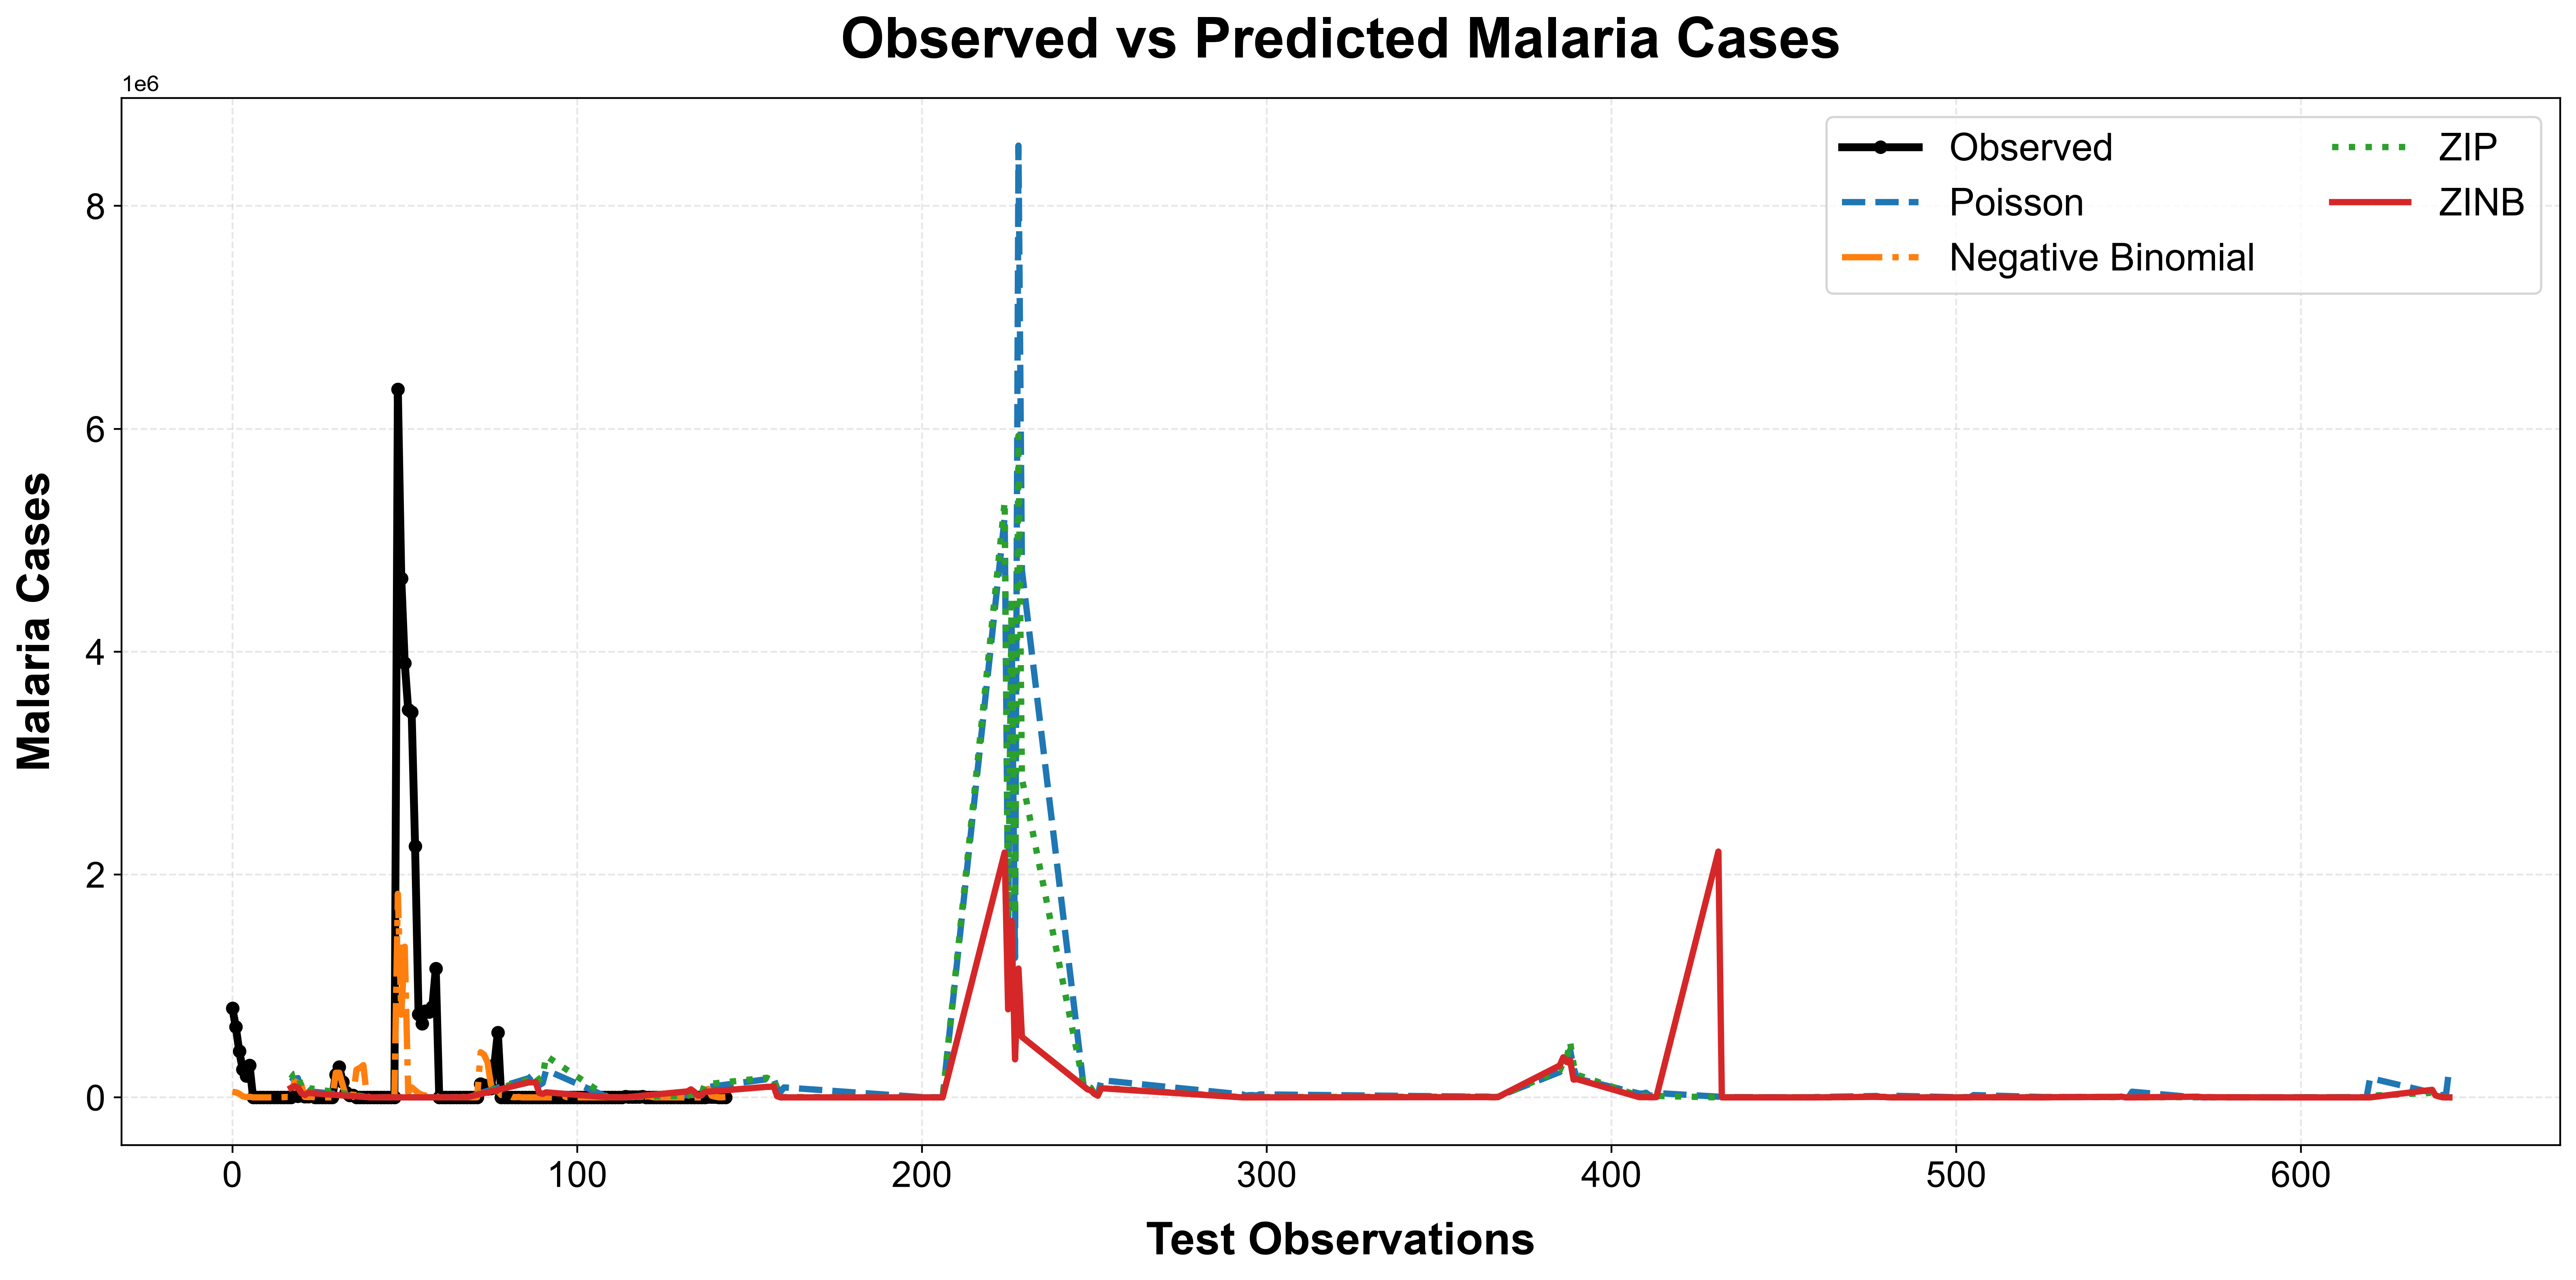

In [ ]:
import matplotlib.pyplot as plt

# Font settings
plt.rcParams["font.family"] = "Arial"

plt.figure(figsize=(16, 8), dpi=400)

# Observed values
plt.plot(y_test.values, label="Observed",
         color="black", linewidth=3.5,
         marker="o", markersize=5)

# Predicted values
plt.plot(pred_p, label="Poisson",
         linewidth=2.8, linestyle="--")

plt.plot(y_pred_nb, label="Negative Binomial",
         linewidth=2.8, linestyle="-.")

plt.plot(zip_pred, label="ZIP",
         linewidth=2.8, linestyle=":")

plt.plot(zinb_pred, label="ZINB",
         linewidth=2.8, linestyle="-")

# Axis labels
plt.xlabel("Test Observations",
           fontsize=20, fontweight="bold", labelpad=12)

plt.ylabel("Malaria Cases",
           fontsize=20, fontweight="bold", labelpad=12)

# Title
plt.title("Observed vs Predicted Malaria Cases",
          fontsize=25, fontweight="bold", pad=18)

# Tick labels
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# Legend
plt.legend(fontsize=17, frameon=True,
           loc="best", ncol=2)

# Grid and layout
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()

# Save high-resolution figure
plt.savefig("Observed_vs_Predicted.png",
            dpi=400, bbox_inches="tight")

plt.show()

In [20]:
import numpy as np
import pandas as pd

# Calculate IRR
irr = np.exp(zinb_result.params)

# Confidence intervals
ci = np.exp(zinb_result.conf_int())

# Create IRR table
irr_table = pd.DataFrame({
    "Coefficient": zinb_result.params,
    "IRR": irr,
    "Lower 95% CI": ci[0],
    "Upper 95% CI": ci[1],
    "P-value": zinb_result.pvalues
})

print(irr_table.round(4))

                Coefficient           IRR  Lower 95% CI  Upper 95% CI  P-value
inflate_const -2.538600e+01  0.000000e+00           NaN           NaN      NaN
inflate_x1    -4.913000e-01  6.118000e-01           NaN           NaN      NaN
inflate_x2    -2.091600e+00  1.235000e-01           NaN           NaN      NaN
inflate_x3     1.010400e+00  2.746600e+00           NaN           NaN      NaN
inflate_x4     1.006600e+00  2.736200e+00           NaN           NaN      NaN
inflate_x5    -3.469000e-01  7.069000e-01           NaN           NaN      NaN
inflate_x6     2.772400e+00  1.599720e+01           NaN           NaN      NaN
inflate_x7     5.470000e-01  1.728100e+00           NaN           NaN      NaN
inflate_x8    -1.514000e+00  2.200000e-01           NaN           NaN      NaN
inflate_x9    -3.875000e-01  6.787000e-01           NaN           NaN      NaN
inflate_x10    5.470000e-01  1.728100e+00           NaN           NaN      NaN
inflate_x11    8.558000e-01  2.353400e+00           

               IRR (95% CI)   p
x1          0.247 (nan-nan) NaN
x2          1.432 (nan-nan) NaN
x3     360837.446 (nan-nan) NaN
x4          0.000 (nan-nan) NaN
x5          0.455 (nan-nan) NaN
x6          0.465 (nan-nan) NaN
x7            inf (nan-nan) NaN
x8          1.137 (nan-nan) NaN
x9          1.029 (nan-nan) NaN
x10         0.000 (nan-nan) NaN
x11         0.000 (nan-nan) NaN
x12           inf (nan-nan) NaN
x13         0.693 (nan-nan) NaN
x14         0.729 (nan-nan) NaN
x15         0.575 (nan-nan) NaN
x16         1.059 (nan-nan) NaN
x17         1.270 (nan-nan) NaN
x18         0.865 (nan-nan) NaN
x19      6233.721 (nan-nan) NaN
x20         0.001 (nan-nan) NaN
x21         0.117 (nan-nan) NaN
alpha       9.906 (nan-nan) NaN


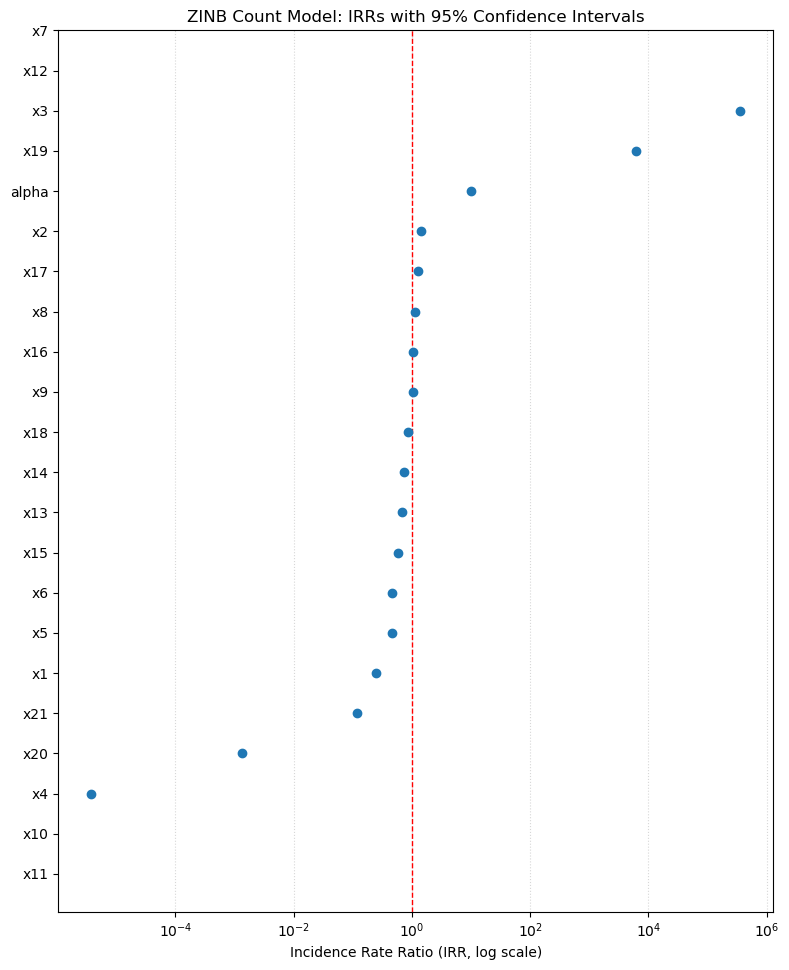

In [ ]:


# Get model coefficients, confidence intervals, and p-values
params = zinb_result.params
ci = zinb_result.conf_int()
p_values = zinb_result.pvalues

# Keep count-model terms only; remove inflation terms and intercept
mask = ~params.index.str.startswith("inflate_") & (params.index != "const")

count_params = params[mask]
count_ci = ci.loc[mask]

# Build the IRR results table
joint = pd.DataFrame({
    "IRR": np.exp(count_params),
    "lo": np.exp(count_ci.iloc[:, 0]),
    "hi": np.exp(count_ci.iloc[:, 1]),
    "p": p_values.loc[mask],
})

# Format IRR and 95% confidence interval
joint["IRR (95% CI)"] = joint.apply(
    lambda row: f"{row['IRR']:.3f} ({row['lo']:.3f}-{row['hi']:.3f})",
    axis=1,
)

print(joint[["IRR (95% CI)", "p"]].round(4))

# Save the table
joint.to_csv(f"{OUT}/zinb_irr_results.csv", index_label="Variable")

# Forest plot
joint = joint.sort_values("IRR")
y = np.arange(len(joint))

fig, ax = plt.subplots(figsize=(8, max(4, 0.4 * len(joint) + 1)))

ax.errorbar(
    joint["IRR"],
    y,
    xerr=[
        joint["IRR"] - joint["lo"],
        joint["hi"] - joint["IRR"],
    ],
    fmt="o",
    capsize=3,
)

ax.axvline(1, color="red", linestyle="--", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(joint.index)
ax.set_xscale("log")
ax.set_xlabel("Incidence Rate Ratio (IRR, log scale)")
ax.set_title("ZINB Count Model: IRRs with 95% Confidence Intervals")
ax.grid(axis="x", linestyle=":", alpha=0.5)

fig.tight_layout()
fig.savefig(f"{OUT}/zinb_irr_forest.png", dpi=300, bbox_inches="tight")
plt.show()